# TDA : Clustering des diagrammes de persistance des scans 3D Caesar
## Femmes

#### Paramètres préliminaires

- Packages nécessaires

In [1]:
import utils
import os

np = utils.importer('numpy')
plt = utils.importer('matplotlib.pyplot')
pickle = utils.importer('pickle')
meshio = utils.importer('meshio')

In [2]:
pathglob = 'E:/TDA/Female/'
all_scans = os.listdir(pathglob)
nb_scans = len(all_scans)

- Fonction qui renvoie le nuage de points du scan

In [3]:
def scan_from_index(i):
    path = pathglob + str(all_scans[i])
    scan = meshio.read(path)
    scan = scan.points
    return scan

### Affichage des scans

- On définit des fonctions qui affichent un scan 3D

In [4]:
def plot_scan_3D_interactive(i):
    scan = scan_from_index(i)
    points_set = utils.point_set(scan)
    points_set.plot(color='green', opacity=0.5, size=2)

### Diagrammes de persistance

- Paramètres de base

In [5]:
min_persistence = 3

* On importe les diagrammes et les diagrammes décolorés précédemment sauvegardés

In [6]:
with open ('./Data/XX.bin', 'rb') as fp:
    X = pickle.load(fp)

with open ('./Data/XX_decolor.bin', 'rb') as fp:
    X_decolor = pickle.load(fp)

### Distance entre les diagrammes (Wasserstein)

* On charge les distances, par homologie, précédemment calculées

In [7]:
with open ('./Data/XX1_Dist_H0.bin', 'rb') as fp:
    dict_dist_0 = pickle.load(fp)
with open ('./Data/XX1_Dist_H1.bin', 'rb') as fp:
    dict_dist_1 = pickle.load(fp)
with open ('./Data/XX1_Dist_H2.bin', 'rb') as fp:
    dict_dist_2 = pickle.load(fp)

* On calcule les distances

In [8]:
dict_dist = {}
for key in dict_dist_1.keys():
    dict_dist[key] = np.sqrt(dict_dist_0[key] + dict_dist_1[key] + dict_dist_2[key])

* On choisit le degré d'homologie

In [9]:
d_d = dict_dist

- On affiche les distances maximum et minimum

In [10]:
max_key = max(d_d, key=d_d.get)
min_key = min(d_d, key=d_d.get)

print("max", max_key, d_d[max_key])
print("min", min_key, d_d[min_key])

max (544, 908) 20.05532154954808
min (121, 959) 1.8673145915594362


- On affiche les scans 3D des plus distants

In [11]:
plot_scan_3D_interactive(max_key[0])
plot_scan_3D_interactive(max_key[1])

- On affiche les scans 3D des plus proches

In [12]:
plot_scan_3D_interactive(min_key[0])
plot_scan_3D_interactive(min_key[1])

### Clustering hiérarchique

- On fait un clustering hiérarchique

In [13]:
dendrogram, linkage, fcluster = utils.importer(
    'scipy.cluster.hierarchy', 'dendrogram', 'linkage', 'fcluster')

plt.rcParams["figure.figsize"] = [15, 10]
plt.rcParams["figure.autolayout"] = True

# on peut utiliser single (min), complete (max), average (moyenne)
_, distances = zip(*sorted(d_d.items()))

In [14]:
Z = linkage(distances, metric='precomputed',
            method='complete', optimal_ordering=True)

- Voici le dendrogramme du clustering

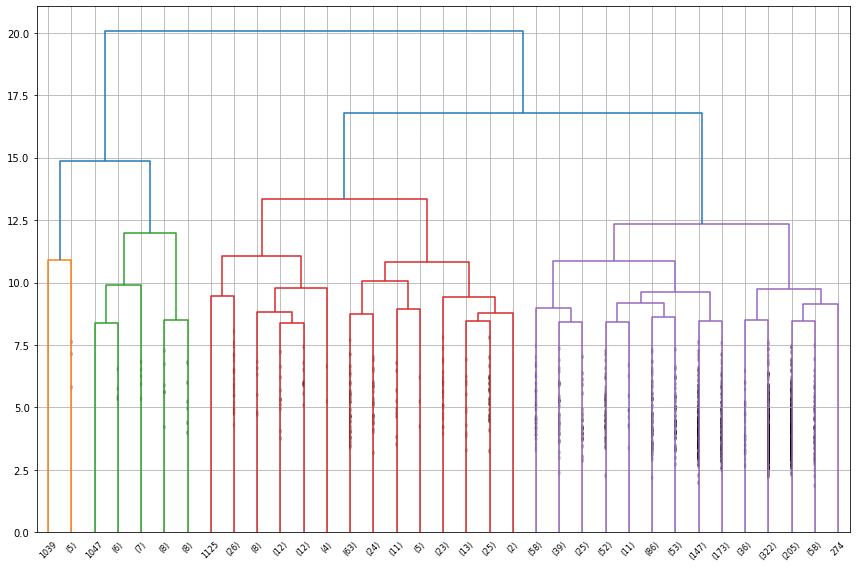

In [40]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(1, 1, 1)
# pour le nb d'individus par branche : show_contracted=True
dendrogram(Z, ax=ax, p=35, truncate_mode='lastp', show_contracted=True)
plt.grid(True)
plt.plot([0, 300], [485, 485], 'r--')
plt.savefig('E:/Projet-M2/2021-m2-ditex-morphotypes/Images/FDENDWARD.jpg');

In [41]:
all_scans[1047]

'SPRING2834.obj'

In [42]:
plot_scan_3D_interactive(1047)

### Courbe elbow du clustering

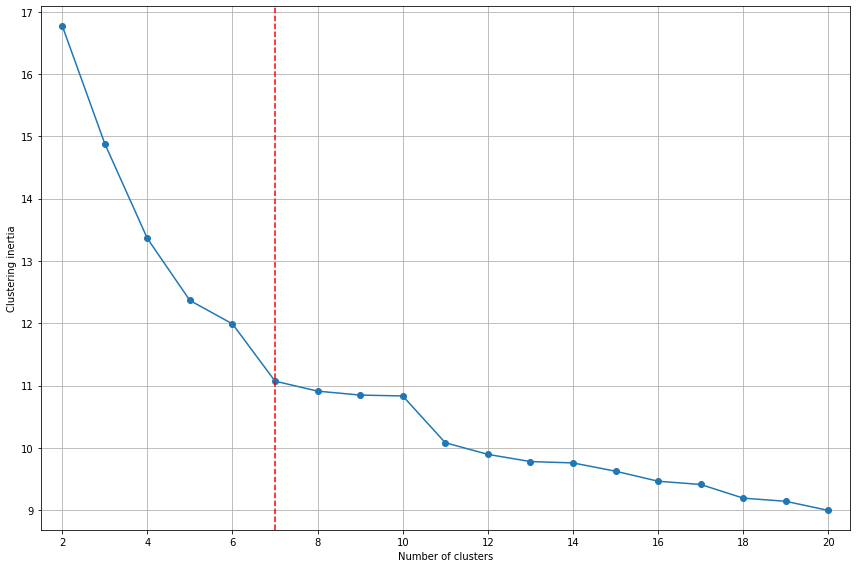

In [17]:
temp = 20

fig = plt.figure(figsize=(12, 8))
ymin, ymax = np.min(Z[::-1, 2][1:temp]), np.max(Z[::-1, 2][1:temp])
a = (ymax - ymin) / 25

plt.plot(range(2, temp+1), Z[::-1, 2][1:temp], 'o-')
plt.plot([7, 7], [ymin-a, ymax+a], 'r--')
plt.ylim(ymin-a, ymax+a)
plt.xticks(range(2, 21, 2))
plt.xlim(1.5, 20.5)
plt.xlabel('Number of clusters')
plt.ylabel('Clustering inertia')
plt.tight_layout()
plt.grid(True)
plt.savefig('E:/Projet-M2/2021-m2-ditex-morphotypes/Images/FWElbow.jpg');

### Indice de Davies-Bouldin

- Voici la courbe associée à cet indice quand on fait varier le nombre de clusters

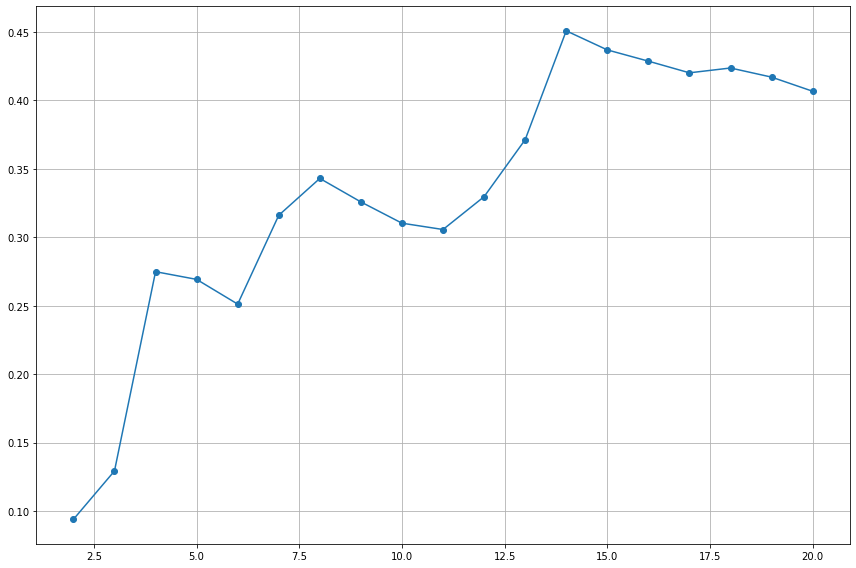

In [18]:
SDB_list = []
borne_nb_clus = 21

for i in range(2, borne_nb_clus):
    nb_clus = i

    clusters = fcluster(Z, nb_clus, criterion='maxclust')
    clusters = clusters.tolist()

    dict_clusters = {}
    for i in range(1, nb_clus+1):
        dict_clusters[i] = []
    for i in range(len(clusters)):
        dict_clusters[clusters[i]].append(i)
    SDB_list.append(utils.indice_DB(dict_clusters, d_d))

plt.figure(figsize=(12, 8))
plt.plot(range(2, borne_nb_clus), SDB_list, 'o-')
plt.grid(True);

- On choisit le nombre de clusters pour le clustering

In [19]:
nb_clus = 6  # À choisir
clusters = fcluster(Z, nb_clus, criterion='maxclust')

- Voici les individus par cluster

In [20]:
dict_clusters = {}
for i in range(1, nb_clus+1):
    dict_clusters[i] = []
for i in range(len(clusters)):
    dict_clusters[clusters[i]].append(i)

for key in dict_clusters:
    print('Cluster n°' + str(key), "de taille", len(
        dict_clusters[key]), ':', dict_clusters[key], '\n')

Cluster n°1 de taille 6 : [370, 773, 790, 908, 1000, 1039] 

Cluster n°2 de taille 30 : [258, 259, 271, 315, 425, 426, 431, 437, 538, 572, 580, 672, 703, 714, 731, 761, 769, 777, 795, 865, 917, 956, 987, 1008, 1034, 1047, 1112, 1123, 1132, 1281] 

Cluster n°3 de taille 63 : [2, 21, 33, 69, 101, 145, 154, 161, 213, 227, 255, 269, 284, 301, 319, 331, 373, 382, 384, 463, 475, 485, 499, 533, 558, 613, 615, 630, 683, 687, 688, 694, 696, 700, 707, 710, 716, 719, 742, 750, 758, 812, 816, 867, 903, 915, 921, 932, 968, 1027, 1031, 1053, 1061, 1069, 1086, 1109, 1113, 1114, 1125, 1309, 1355, 1449, 1469] 

Cluster n°4 de taille 166 : [25, 27, 40, 52, 62, 87, 122, 129, 136, 168, 176, 177, 194, 198, 201, 209, 231, 232, 239, 247, 251, 257, 260, 262, 272, 278, 288, 303, 313, 314, 321, 328, 334, 345, 347, 352, 361, 365, 374, 388, 393, 403, 408, 410, 414, 434, 446, 453, 465, 468, 481, 483, 486, 489, 492, 517, 526, 528, 539, 541, 548, 567, 570, 573, 584, 588, 595, 604, 614, 636, 644, 659, 673, 675, 681, 

### Centre des clusters

In [21]:
medoids = []
for i in dict_clusters:
    medoid = utils.cluster_medoid(dict_clusters[i], d_d)
    medoids.append(medoid)
    print("Le cluster", i, "est de longueur", str(len(
        dict_clusters[i]))+", son médoïde est l'individu", medoid, "et voici son scan")
    plot_scan_3D_interactive(medoid)

Le cluster 1 est de longueur 6, son médoïde est l'individu 790 et voici son scan


Le cluster 2 est de longueur 30, son médoïde est l'individu 1034 et voici son scan


Le cluster 3 est de longueur 63, son médoïde est l'individu 1449 et voici son scan


Le cluster 4 est de longueur 166, son médoïde est l'individu 1421 et voici son scan


Le cluster 5 est de longueur 644, son médoïde est l'individu 1500 et voici son scan


Le cluster 6 est de longueur 622, son médoïde est l'individu 895 et voici son scan


In [22]:
for k, index in enumerate(medoids):
    print(k, ':', index, '-', all_scans[index], '->', len(
        dict_clusters[k+1]), len(
        dict_clusters[k+1])/15.31)

0 : 790 - SPRING2424.obj -> 6 0.3919007184846505
1 : 1034 - SPRING2816.obj -> 30 1.9595035924232527
2 : 1449 - SPRING4664.obj -> 63 4.11495754408883
3 : 1421 - SPRING4606.obj -> 166 10.842586544741998
4 : 1500 - SPRING4753.obj -> 644 42.06401045068583
5 : 895 - SPRING2579.obj -> 622 40.62704114957544


## K-Medoids

In [23]:
# KMedoids = utils.importer('sklearn_extra.cluster', 'KMedoids')

# distance = np.zeros((nb_scans, nb_scans))

# for i in range(nb_scans):
#     for j in range(i+1, nb_scans):
#         distance[i, j] = distance[j, i] = d_d[(i, j)]

In [24]:
# KElbowVisualizer = utils.importer('yellowbrick.cluster', 'KElbowVisualizer')

# model = KMedoids(metric='precomputed', method='pam')
# visualizer = KElbowVisualizer(model, k=(2, 16), timings=False)

# visualizer.fit(distance)   # Fit the data to the visualizer
# visualizer.show();         # Finalize and render the figure

In [25]:
# nb_clus = 5

# kmed = KMedoids(n_clusters=nb_clus, metric='precomputed', method='pam').fit(distance)
# clusters = kmed.labels_

In [26]:
# dict_clusters = {}
# for i in range(1, nb_clus+1):
#     dict_clusters[i] = []
# for i in range(len(clusters)):
#     dict_clusters[clusters[i]+1].append(i)

# for key in dict_clusters:
#     print('Cluster n°' + str(key), "de taille", len(
#         dict_clusters[key]), ':', dict_clusters[key], '\n')

In [27]:
# indices = kmed.medoid_indices_

# for i in range(indices.shape[0]):
#     medoid = indices[i]
#     print("Le cluster", i+1, "est de longueur", str(len(
#         dict_clusters[i+1]))+", son médoïde est l'individu", medoid, "et voici son scan")
#     plot_scan_3D_interactive(medoid)